# Walk-Rear Imitation Rollout

Extract the frozen imitation encoder+decoder from a walk_rear task transfer
checkpoint, select reference motion clips, preview them, and run
encoder+decoder imitation rollouts with ghost overlay.

In [98]:
%load_ext autoreload
%autoreload 2

import functools
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np
import mediapy as media
import orbax.checkpoint as ocp
import plotly.graph_objects as go
from matplotlib.backends.backend_agg import FigureCanvasAgg
from ml_collections import ConfigDict
from mujoco import mjx
from omegaconf import OmegaConf
from sklearn.decomposition import PCA

from brax.training.agents.ppo import networks as ppo_networks
from brax.training.acme import running_statistics, specs

from scamper.agent import checkpointing
from scamper.agent.task_transfer.walk_rear.checkpoint_utils import (
    load_task_transfer_metadata,
    _create_abstract_prior_policy,
    _STEP_PREFIX,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    load_task_transfer_brax_params,
)
from scamper.agent.task_transfer.walk_rear.wrappers import (
    DecoderHighLevelWrapper,
    PriorDecoderHighLevelWrapper,
    _flatten_obs_for_policy,
)
from scamper.analysis import rollout
from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import imitation, walk_rear
from vnl_playground.tasks.reference_clips import ReferenceClips

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [150]:
# ============ CHECKPOINT ============
# Path to the walk_rear task transfer checkpoint directory
WALK_REAR_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260210_123915_445695"

# Checkpoint step to load (None = latest)
CHECKPOINT_STEP = 5

# ============ REFERENCE DATA ============
# Override reference data path (None = use path from checkpoint config)
REFERENCE_DATA_PATH = None

# Path prefix replacement for checkpoints saved on a different machine.
# Set both to None to skip path fixing.
OLD_PATH_PREFIX = "/tmp/track-mjx"  # e.g., "/tmp/scamper"
NEW_PATH_PREFIX = "/home/mila/a/aidan.sirbu/SCAMPER"  # e.g., "/home/user/scamper"

# ============ ENVIRONMENT OVERRIDES ============
# MuJoCo backend: "jax" or "warp" (None = use checkpoint default)
MUJOCO_IMPL = "warp"

# Walker XML variant (None = use checkpoint default)
# Options: "rodent.xml", "rodent_full_collisions.xml",
#          "rodent_no_tail_collisions.xml", "rodent_box_feet.xml"
WALKER_XML = "rodent_no_tail_collisions.xml"

# ============ ROLLOUT SETTINGS ============
DETERMINISTIC = True  # Use mean action (no sampling from encoder)

# ============ RENDERING ============
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50
CAMERA_NAME = "close_profile-rodent"

## Load Frozen Networks from Task Transfer Checkpoint

In [151]:
# 1. Load metadata (JSON only, lightweight)
metadata = load_task_transfer_metadata(WALK_REAR_CHECKPOINT_PATH, CHECKPOINT_STEP)
config = metadata["config"]
step = metadata["step"]
ckpt_cfg = config["checkpoint_config"]
ckpt_cfg_omega = OmegaConf.create(ckpt_cfg)

print(f"Loaded metadata from step {step}")
print(f"Training mode: {config.get('mode', 'unknown')}")
print(f"Latent size: {ckpt_cfg['network_config']['intention_size']}")
print(f"Action size: {ckpt_cfg['network_config']['action_size']}")

# 2. Fix paths if needed
OmegaConf.set_struct(ckpt_cfg_omega, False)

if REFERENCE_DATA_PATH is not None:
    OmegaConf.update(
        ckpt_cfg_omega, "env_config.reference_data_path", REFERENCE_DATA_PATH
    )

if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:

    def fix_path(p):
        if p and p.startswith(OLD_PATH_PREFIX):
            return p.replace(OLD_PATH_PREFIX, NEW_PATH_PREFIX, 1)
        return p

    for key in ["walker_xml_path", "arena_xml_path", "reference_data_path"]:
        OmegaConf.update(
            ckpt_cfg_omega,
            f"env_config.{key}",
            fix_path(ckpt_cfg_omega.env_config[key]),
        )

# Auto-fix XML paths if they don't exist on disk (e.g. checkpoint saved with
# a different install prefix). Falls back to the installed vnl_playground paths,
# matching the original filename to preserve the correct XML variant.
_xml_lookup = {
    "rodent_full_collisions.xml": str(rodent_consts.RODENT_FULL_COLLISION_XML),
    "rodent_no_tail_collisions.xml": str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML),
    "rodent_box_feet.xml": str(rodent_consts.RODENT_BOX_FEET_PATH),
    "rodent.xml": str(rodent_consts.RODENT_XML_PATH),
    "arena.xml": str(rodent_consts.ARENA_XML_PATH),
}

for key in ["walker_xml_path", "arena_xml_path"]:
    current = ckpt_cfg_omega.env_config[key]
    if not Path(current).exists():
        filename = Path(current).name
        fallback = _xml_lookup.get(filename)
        if fallback is not None:
            OmegaConf.update(ckpt_cfg_omega, f"env_config.{key}", fallback)
            print(f"Fixed {key}: {filename} -> {fallback}")
        else:
            print(f"Warning: {key} not found and no fallback for '{filename}'")

# 3. Apply environment overrides from Configuration cell
if MUJOCO_IMPL is not None:
    OmegaConf.update(ckpt_cfg_omega, "env_config.mujoco_impl", MUJOCO_IMPL)

if WALKER_XML is not None:
    resolved = _xml_lookup.get(WALKER_XML)
    if resolved is not None:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", resolved)
    else:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", WALKER_XML)

print(f"\nPaths:")
print(f"  walker_xml: {ckpt_cfg_omega.env_config.walker_xml_path}")
print(f"  arena_xml: {ckpt_cfg_omega.env_config.arena_xml_path}")
print(f"  reference_data: {ckpt_cfg_omega.env_config.reference_data_path}")
print(f"  mujoco_impl: {ckpt_cfg_omega.env_config.mujoco_impl}")

# 4. Create abstract pytree structure for restoring frozen networks
abstract_policy = _create_abstract_prior_policy(ckpt_cfg_omega)
normalizer_state, combined_params = abstract_policy

abstract_frozen_networks = {
    "encoder_params": combined_params["params"]["encoder"],
    "prior_params": combined_params["params"]["prior"],
    "decoder_params": combined_params["params"]["decoder"],
    "imitation_normalizer": normalizer_state,
}

# 5. Restore frozen networks from task transfer checkpoint
mgr_options = ocp.CheckpointManagerOptions(create=False, step_prefix=_STEP_PREFIX)
with ocp.CheckpointManager(WALK_REAR_CHECKPOINT_PATH, options=mgr_options) as mgr:
    restored = mgr.restore(
        step,
        args=ocp.args.Composite(
            frozen_networks=ocp.args.StandardRestore(abstract_frozen_networks),
        ),
    )

frozen = restored["frozen_networks"]
encoder_params = frozen["encoder_params"]
decoder_params = frozen["decoder_params"]
imitation_normalizer = frozen["imitation_normalizer"]

encoder_count = sum(p.size for p in jax.tree_util.tree_leaves(encoder_params))
decoder_count = sum(p.size for p in jax.tree_util.tree_leaves(decoder_params))
print(f"\nFrozen networks loaded successfully")
print(f"  Encoder parameters: {encoder_count:,}")
print(f"  Decoder parameters: {decoder_count:,}")

Loaded metadata from step 5
Training mode: prior_decoder
Latent size: 16
Action size: 38
Fixed walker_xml_path: rodent.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent.xml
Fixed arena_xml_path: arena.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml

Paths:
  walker_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent_no_tail_collisions.xml
  arena_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml
  reference_data: /home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5
  mujoco_impl: warp

Frozen networks loaded successfully
  Encoder parameters: 4,501,536
  Decoder parameters: 1,919,564


## Load Reference Clips

In [152]:
reference_data_path = ckpt_cfg_omega.env_config.reference_data_path
clip_length = ckpt_cfg_omega.env_config.clip_length

reference_clips = ReferenceClips(
    data_path=reference_data_path,
    n_frames_per_clip=clip_length,
)

clip_names = reference_clips.clip_names
if clip_names is not None:
    behavior_counts = {}
    for name in clip_names:
        behavior_counts[name] = behavior_counts.get(name, 0) + 1

    print(f"Total clips: {len(clip_names)}")
    print(f"Clip length: {clip_length} frames")
    print(f"\nBehavior types:")
    for behavior, count in sorted(behavior_counts.items(), key=lambda x: -x[1]):
        print(f"  {behavior}: {count} clips")
else:
    n_clips = reference_clips.qpos.shape[0]
    print(f"Total clips: {n_clips}")
    print(f"Clip length: {clip_length} frames")
    print("(clip_names not available for this dataset)")

Total clips: 842
Clip length: 250 frames

Behavior types:
  FastWalk: 189 clips
  Walk: 174 clips
  Rear: 165 clips
  FaceGroom: 136 clips
  RGroom: 96 clips
  LGroom: 82 clips


## Select Clips

In [168]:
def get_clip_indices_by_behavior(clips, behavior_name):
    """Get clip indices for a given behavior name."""
    names = clips.clip_names
    if names is None:
        raise ValueError("clip_names not available for this dataset")
    return np.where(names == behavior_name)[0]


# ============ EDIT SELECTION HERE ============
rear_indices = get_clip_indices_by_behavior(reference_clips, "Rear")

selected_indices = [
    #rear_indices[0],
    rear_indices[7],
]
# =============================================

print(f"Selected {len(selected_indices)} clips:")
for i, idx in enumerate(selected_indices):
    name = clip_names[idx] if clip_names is not None else f"clip_{idx}"
    print(f"  [{i}] clip {idx}: {name}")

Selected 1 clips:
  [0] clip 27: Rear


## Create Imitation Environment

In [169]:
env_cfg_ml = ConfigDict(OmegaConf.to_container(ckpt_cfg_omega.env_config, resolve=True))

# naconmax (allocated contact buffer size) is typically set at training time as
# nconmax * num_envs.  For single-environment rollouts set it to nconmax.
if "naconmax" not in env_cfg_ml:
    env_cfg_ml.naconmax = env_cfg_ml.get("nconmax", 200)

env = imitation.Imitation(config=env_cfg_ml, clips=reference_clips)

print(f"Environment created")
print(f"  Action size: {env.action_size}")
print(f"  Observation size: {env.observation_size}")

print(f"\nAvailable cameras:")
for i in range(env.mj_model.ncam):
    print(f"  {i}: {env.mj_model.camera(i).name}")

Environment created
  Action size: 38
  Observation size: 917

Available cameras:
  0: close_profile-rodent
  1: back-rodent
  2: side-rodent
  3: close_side_hind_R-rodent
  4: close_side_front_R-rodent
  5: close_side_hind_L-rodent
  6: close_side_front_L-rodent
  7: side_alt-rodent
  8: top-rodent
  9: egocentric-rodent


## Preview Reference Motions

Render raw mocap reference data (no simulation) to verify clip selection.

In [170]:
model = env.mj_model
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    cam_id = 0

for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    frames = []

    for frame_idx in range(clip_length):
        ref = reference_clips.at(clip=clip_idx, frame=frame_idx)
        data.qpos[:] = np.array(ref.qpos)
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, camera=cam_id)
        frame = renderer.render()
        frames.append(frame.copy())

    print(f"Clip {clip_idx} ({clip_name})")
    media.show_video(frames, fps=RENDER_FPS)

renderer.close()

Clip 27 (Rear)


This browser does not support the video tag.


## Create Encoder+Decoder Inference Function

In [171]:
# Reconstruct imitation policy params:
#   (normalizer, {"params": {"encoder": ..., "decoder": ...}})
policy_params = (
    imitation_normalizer,
    {"params": {"encoder": encoder_params, "decoder": decoder_params}},
)

# load_inference_fn builds the full PPO network (policy + value) even though only
# the policy is used for inference.  Ensure critic_layer_sizes exists in the config.
if "critic_layer_sizes" not in ckpt_cfg_omega.network_config:
    OmegaConf.update(
        ckpt_cfg_omega,
        "network_config.critic_layer_sizes",
        [1024, 512, 256],
    )

inference_fn = checkpointing.load_inference_fn(
    ckpt_cfg_omega, policy_params, deterministic=DETERMINISTIC
)

print(f"Inference function created (deterministic={DETERMINISTIC})")

Inference function created (deterministic=True)


## Run Imitation Rollouts

The first call triggers JAX compilation (~1-3 min). Subsequent calls are fast.

In [172]:
generate_rollout = rollout.create_rollout_generator(
    ckpt_cfg_omega,
    env,
    inference_fn,
    log_full_states=True,
    log_activations=False,
    log_metrics=False,
)

rollout_results = {}
for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    print(f"Running rollout for clip {clip_idx} ({clip_name})...", end=" ")
    result = generate_rollout(clip_idx=clip_idx)
    rollout_results[clip_idx] = result
    avg_reward = float(jnp.mean(result["state_rewards"]))
    print(f"avg reward: {avg_reward:.4f}")

Running rollout for clip 27 (Rear)... avg reward: 4.5231


## Render Rollouts with Ghost Overlay

The reference motion is shown as a white transparent ghost alongside the
simulated (teal) rollout.

In [173]:
def _stamp_frame(frame, text, fontsize=14):
    """Draw text onto a frame using matplotlib."""
    h, w = frame.shape[:2]
    dpi = 100
    fig = plt.Figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(frame)
    ax.text(
        10, 28, text, fontsize=fontsize, color="white",
        fontweight="bold", family="monospace",
        bbox=dict(facecolor="black", alpha=0.5, pad=2, edgecolor="none"),
    )
    ax.axis("off")
    canvas.draw()
    buf = np.frombuffer(canvas.buffer_rgba(), dtype=np.uint8).reshape(h, w, 4)
    plt.close(fig)
    return buf[:, :, :3]


for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    result = rollout_results[clip_idx]
    states = result["rollout_states"]

    # Convert stacked states to list of individual states
    num_timesteps = states.data.qpos.shape[0]
    states_list = [
        jax.tree_util.tree_map(lambda x: x[t], states) for t in range(num_timesteps)
    ]

    raw_frames = env.render(
        states_list,
        camera=CAMERA_NAME,
        height=RENDER_HEIGHT,
        width=RENDER_WIDTH,
        render_ghost=True,
    )

    # Add timestep text to each frame
    frames = [_stamp_frame(np.array(f), f"t={t}") for t, f in enumerate(raw_frames)]

    avg_reward = float(jnp.mean(result["state_rewards"]))
    print(f"Clip {clip_idx} ({clip_name}) — avg reward: {avg_reward:.4f}")
    media.show_video(frames, fps=RENDER_FPS)

Clip 27 (Rear) — avg reward: 4.5231


This browser does not support the video tag.


In [174]:
# Extract joint angles from imitation rollouts for later comparison
ROOT_QPOS_SIZE = 7  # 3 position + 4 quaternion for root body

joint_angle_trajs = {}
for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    states = rollout_results[clip_idx]["rollout_states"]
    qposes = np.array(states.data.qpos)
    joint_angle_trajs[clip_idx] = qposes[:, ROOT_QPOS_SIZE:]

print(f"Extracted joint angle trajectories for {len(joint_angle_trajs)} clips")
for clip_idx, joints in joint_angle_trajs.items():
    print(f"  clip {clip_idx}: {joints.shape}")

Extracted joint angle trajectories for 1 clips
  clip 27: (499, 67)


## Walk-Rear Task Rollout

Run the full walk_rear task transfer policy (prior + residual → decoder → ctrl)
to compare its joint-angle trajectory against the imitation rollouts.

In [175]:
# --- Create WalkRear environment ---
wr_env_cfg = walk_rear.default_config()

task_cfg = config  # full task transfer config from checkpoint metadata
ckpt_cfg_dict = OmegaConf.to_container(ckpt_cfg_omega, resolve=True)
latent_size = ckpt_cfg_dict["network_config"]["intention_size"]
proprio_size = ckpt_cfg_dict["network_config"]["obs_sizes"]["proprioception"]

# Apply task env settings from checkpoint
wr_env_cfg.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
wr_env_cfg.target_x = task_cfg["env"]["target_x"]
wr_env_cfg.target_y = task_cfg["env"]["target_y"]
wr_env_cfg.target_z = task_cfg["env"]["target_z"]
wr_env_cfg.xy_tolerance = task_cfg["env"]["xy_tolerance"]
wr_env_cfg.z_tolerance = task_cfg["env"]["z_tolerance"]
wr_env_cfg.hold_duration = task_cfg["env"]["hold_duration"]
wr_env_cfg.distance_margin = task_cfg["env"]["distance_margin"]
wr_env_cfg.reward_terms = {
    "distance_to_target": {
        "weight": task_cfg["env"]["reward_weights"]["distance_to_target"]
    },
    "walk_rear_success": {
        "weight": task_cfg["env"]["reward_weights"]["walk_rear_success"]
    },
}

# Apply same environment overrides as imitation rollouts.
# WalkRear default_config uses PosixGPath for XML paths, so use the
# rodent_consts paths directly (not stringified _xml_lookup values).
_wr_xml_lookup = {
    "rodent_full_collisions.xml": rodent_consts.RODENT_FULL_COLLISION_XML,
    "rodent_no_tail_collisions.xml": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
    "rodent_box_feet.xml": rodent_consts.RODENT_BOX_FEET_PATH,
    "rodent.xml": rodent_consts.RODENT_XML_PATH,
}

if MUJOCO_IMPL is not None:
    wr_env_cfg.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    wr_env_cfg.walker_xml_path = _wr_xml_lookup.get(WALKER_XML, WALKER_XML)

wr_base_env = walk_rear.WalkRear(config=wr_env_cfg)

# --- Wrap with the appropriate wrapper based on training mode ---
training_mode = config.get("mode", "prior_decoder")

wr_decoder_fn = make_decoder_inference_fn(
    decoder_params, imitation_normalizer, ckpt_cfg_dict
)

if training_mode == "prior_decoder":
    wr_prior_fn = make_prior_inference_fn(
        frozen["prior_params"], imitation_normalizer, ckpt_cfg_dict
    )
    wr_env = PriorDecoderHighLevelWrapper(
        wr_base_env,
        wr_prior_fn,
        wr_decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=task_cfg.get("prior_decoder", {}).get(
            "deterministic_prior", True
        ),
        noise_logvar=task_cfg.get("prior_decoder", {}).get("noise_logvar", -2.0),
    )
elif training_mode == "decoder_only":
    wr_env = DecoderHighLevelWrapper(
        wr_base_env,
        wr_decoder_fn,
        latent_size,
        proprio_size,
    )
else:
    raise ValueError(
        f"Unsupported training mode for walk_rear rollout: '{training_mode}'. "
        f"Expected 'prior_decoder' or 'decoder_only'."
    )

print(f"WalkRear wrapped env created (mode: {training_mode})")
print(f"  Obs size: {wr_env.observation_size}, Action size (latent): {wr_env.action_size}")
print(
    f"  Target: ({wr_env_cfg.target_x}, {wr_env_cfg.target_y}, {wr_env_cfg.target_z})"
)

# --- Load brax_params from task transfer checkpoint ---
normalize_fn = (
    running_statistics.normalize
    if task_cfg["train"].get("normalize_observations", True)
    else lambda x, y: x
)

jit_wr_reset = jax.jit(wr_env.reset)
jit_wr_step = jax.jit(wr_env.step)
wr_start_state = jit_wr_reset(jax.random.PRNGKey(0))

obs_size_wr = wr_start_state.obs.shape[-1]
action_size_wr = wr_env.action_size

ppo_net = ppo_networks.make_ppo_networks(
    obs_size_wr,
    action_size_wr,
    preprocess_observations_fn=normalize_fn,
    policy_hidden_layer_sizes=tuple(task_cfg["network"]["policy_layers"]),
    value_hidden_layer_sizes=tuple(task_cfg["network"]["value_layers"]),
)

# Build abstract pytree for Orbax restoration
key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
abstract_normalizer = running_statistics.init_state(
    specs.Array(wr_start_state.obs.shape[-1:], jnp.dtype("float32"))
)
abstract_policy_params = ppo_net.policy_network.init(key_p)
abstract_value_params = ppo_net.value_network.init(key_v)
abstract_brax_params = (abstract_normalizer, abstract_policy_params, abstract_value_params)

brax_params = load_task_transfer_brax_params(
    WALK_REAR_CHECKPOINT_PATH,
    abstract_brax_params,
    step=step,
)

param_count = sum(p.size for p in jax.tree_util.tree_leaves(brax_params[1]))
print(f"\nBrax PPO params loaded (policy: {param_count:,} parameters)")

WalkRear wrapped env created (mode: prior_decoder)
  Obs size: 334, Action size (latent): 16
  Target: (0.5, 0.0, 0.2)

Brax PPO params loaded (policy: 3,325,472 parameters)


In [176]:
# ============ MATCH IMITATION SETTINGS ============
MATCH_IMITATION = True       # Initialize from imitation rollout pose
MATCH_IMITATION_FRAME = 120   # Frame index from imitation rollout to match
# ==================================================

# Build deterministic inference function for walk_rear policy
wr_policy_network = ppo_net.policy_network
wr_action_dist = ppo_net.parametric_action_distribution


def walk_rear_policy(params, observations, key_sample):
    del key_sample
    param_subset = (params[0], params[1])
    logits = wr_policy_network.apply(*param_subset, observations)
    return wr_action_dist.mode(logits), {}


jit_wr_inference = jax.jit(walk_rear_policy)

# Run rollout — match length to the imitation rollouts
wr_episode_length = next(iter(joint_angle_trajs.values())).shape[0]
print(f"Running walk_rear rollout for {wr_episode_length} steps...")

rng = jax.random.PRNGKey(42)
rng, reset_rng = jax.random.split(rng)
state = jit_wr_reset(reset_rng)

if MATCH_IMITATION:
    # Get qpos from imitation rollout at specified frame
    imit_clip_idx = int(selected_indices[0])
    imit_qpos = jnp.array(
        rollout_results[imit_clip_idx]["rollout_states"].data.qpos[MATCH_IMITATION_FRAME]
    )

    # Place root (x, y) directly under the goal; keep z, quaternion, and
    # all joint angles from the imitation frame
    new_qpos = imit_qpos.at[0].set(wr_env_cfg.target_x)
    new_qpos = new_qpos.at[1].set(wr_env_cfg.target_y)

    # Replace physics state and recompute forward kinematics
    new_data = state.data.replace(
        qpos=new_qpos,
        qvel=jnp.zeros_like(state.data.qvel),
    )
    new_data = mjx.forward(wr_base_env.mjx_model, new_data)

    # Recompute observations from base env and flatten for wrapper
    new_obs = wr_base_env._get_obs(new_data, state.info)
    state = state.replace(data=new_data, obs=_flatten_obs_for_policy(new_obs))

    print(
        f"Initialized from imitation frame {MATCH_IMITATION_FRAME} "
        f"(clip {imit_clip_idx}), placed under goal"
    )

qposes_wr = [np.array(state.data.qpos)]
rewards_wr = []

for t in range(wr_episode_length - 1):
    rng, act_rng = jax.random.split(rng)
    action, _ = jit_wr_inference(brax_params, state.obs, act_rng)
    state = jit_wr_step(state, action)
    qposes_wr.append(np.array(state.data.qpos))
    rewards_wr.append(float(state.reward))

qposes_wr = np.stack(qposes_wr, axis=0)
rewards_wr = np.array(rewards_wr)

print(f"Walk-Rear rollout complete")
print(f"  qpos shape: {qposes_wr.shape}")
print(f"  avg reward: {rewards_wr.mean():.4f}")

Running walk_rear rollout for 499 steps...
Initialized from imitation frame 120 (clip 27), placed under goal
Walk-Rear rollout complete
  qpos shape: (499, 74)
  avg reward: 0.8632


In [177]:
# Render walk_rear rollout
wr_model = wr_base_env.mj_model
wr_data = mujoco.MjData(wr_model)
wr_renderer = mujoco.Renderer(wr_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

wr_cam_id = mujoco.mj_name2id(wr_model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if wr_cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    wr_cam_id = 0

frames = []
for t in range(len(qposes_wr)):
    wr_data.qpos[:] = np.array(qposes_wr[t])
    mujoco.mj_forward(wr_model, wr_data)
    wr_renderer.update_scene(wr_data, camera=wr_cam_id)
    frame = wr_renderer.render().copy()
    frames.append(_stamp_frame(frame, f"t={t}"))

wr_renderer.close()

print(f"Walk-Rear rollout — avg reward: {rewards_wr.mean():.4f}")
media.show_video(frames, fps=RENDER_FPS)

Walk-Rear rollout — avg reward: 0.8632


This browser does not support the video tag.


## Joint PCA — Imitation + Walk-Rear

Fit PCA on joint angles from all imitation rollouts **and** the walk_rear
rollout. Each plot shows one imitation trajectory (coloured by time) with
the walk_rear trajectory overlaid in red/orange.

In [178]:
# ============ EDIT TIME RANGES HERE ============
# Timestep ranges for PCA analysis. Set to None for no bound.
IMIT_T_START = 130 # e.g. 0
IMIT_T_END = 230  # e.g. 250
WR_T_START = 0  # e.g. 50
WR_T_END = 80  # e.g. 300
# ===============================================

imit_t0 = IMIT_T_START if IMIT_T_START is not None else 0
wr_t0 = WR_T_START if WR_T_START is not None else 0

# Extract walk_rear joint angles (strip root qpos), apply time range
wr_joint_angles = qposes_wr[wr_t0:WR_T_END, ROOT_QPOS_SIZE:]

# Apply time range to imitation trajectories
joint_angle_trajs_sliced = {}
for clip_idx, joints in joint_angle_trajs.items():
    joint_angle_trajs_sliced[clip_idx] = joints[imit_t0:IMIT_T_END]

# Combine all joint angles for a shared PCA
all_joint_angles = list(joint_angle_trajs_sliced.values()) + [wr_joint_angles]
all_joints_combined = np.concatenate(all_joint_angles, axis=0)

# Fit PCA
pca_combined = PCA(n_components=3)
pca_combined.fit(all_joints_combined)

explained = pca_combined.explained_variance_ratio_
imit_range_str = f"t={imit_t0}:{IMIT_T_END if IMIT_T_END is not None else 'end'}"
wr_range_str = f"t={wr_t0}:{WR_T_END if WR_T_END is not None else 'end'}"
print(
    f"Combined PCA — imit [{imit_range_str}], walk_rear [{wr_range_str}]"
)
print(
    f"Explained variance: "
    f"PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, PC3={explained[2]:.1%}"
)
print(f"Total: {sum(explained):.1%}")

# Project each imitation rollout
projected_imit = {}
for clip_idx, joints in joint_angle_trajs_sliced.items():
    projected_imit[clip_idx] = pca_combined.transform(joints)

# Project walk_rear rollout
projected_wr = pca_combined.transform(wr_joint_angles)
print(f"\nImitation rollouts: {len(projected_imit)} x {next(iter(projected_imit.values())).shape}")
print(f"Walk-Rear rollout: {projected_wr.shape}")

Combined PCA — imit [t=130:230], walk_rear [t=0:80]
Explained variance: PC1=52.0%, PC2=28.9%, PC3=8.0%
Total: 88.9%

Imitation rollouts: 1 x (100, 3)
Walk-Rear rollout: (80, 3)


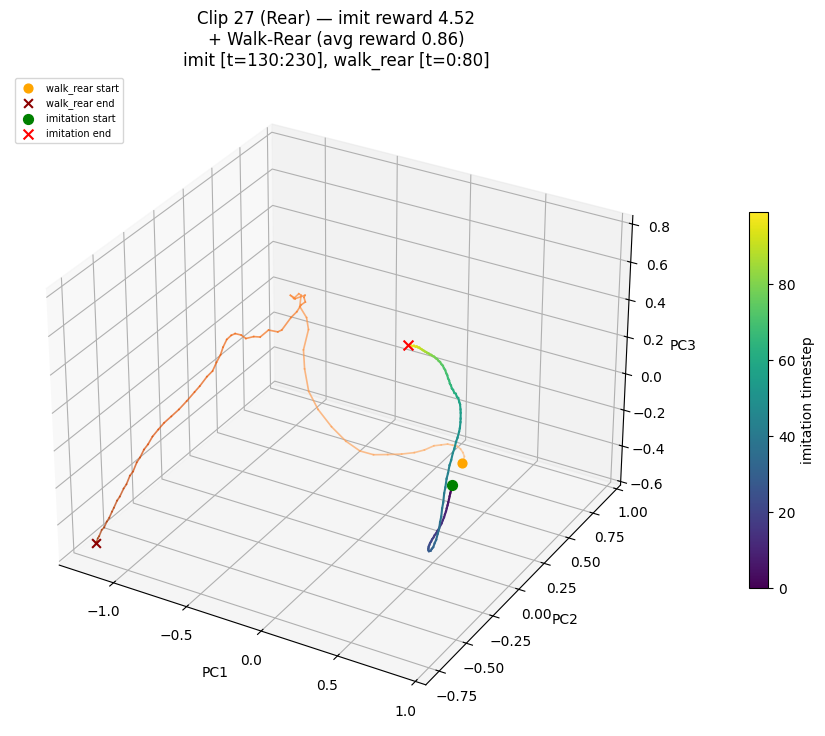

In [179]:
# Plot each imitation rollout with walk_rear overlay
for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    pc_imit = projected_imit[clip_idx]
    T_imit = len(pc_imit)
    T_wr = len(projected_wr)

    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot(111, projection="3d")

    # --- Walk-Rear trajectory (orange, behind) ---
    for t in range(T_wr - 1):
        frac = t / max(T_wr - 1, 1)
        ax.plot(
            projected_wr[t : t + 2, 0],
            projected_wr[t : t + 2, 1],
            projected_wr[t : t + 2, 2],
            color=plt.cm.Oranges(0.3 + 0.6 * frac),
            lw=1.2,
            alpha=0.7,
        )
    ax.scatter(
        *projected_wr[0], s=40, c="orange", marker="o", zorder=4, label="walk_rear start"
    )
    ax.scatter(
        *projected_wr[-1], s=40, c="darkred", marker="x", zorder=4, label="walk_rear end"
    )

    # --- Imitation trajectory (viridis, on top) ---
    for t in range(T_imit - 1):
        frac = t / max(T_imit - 1, 1)
        ax.plot(
            pc_imit[t : t + 2, 0],
            pc_imit[t : t + 2, 1],
            pc_imit[t : t + 2, 2],
            color=plt.cm.viridis(frac),
            lw=1.5,
        )
    ax.scatter(
        *pc_imit[0], s=50, c="green", marker="o", zorder=5, label="imitation start"
    )
    ax.scatter(
        *pc_imit[-1], s=50, c="red", marker="x", zorder=5, label="imitation end"
    )

    # Colorbar for imitation time
    sm = plt.cm.ScalarMappable(
        cmap=plt.cm.viridis, norm=plt.Normalize(0, T_imit - 1)
    )
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.1)
    cbar.set_label("imitation timestep")

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    avg_reward = float(jnp.mean(rollout_results[clip_idx]["state_rewards"]))
    ax.set_title(
        f"Clip {clip_idx} ({clip_name}) — imit reward {avg_reward:.2f}\n"
        f"+ Walk-Rear (avg reward {rewards_wr.mean():.2f})\n"
        f"imit [{imit_range_str}], walk_rear [{wr_range_str}]"
    )
    ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout()
    plt.show()

In [180]:
# Interactive 3D PCA plot with plotly
for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    pc_imit = projected_imit[clip_idx]
    T_imit = len(pc_imit)
    T_wr = len(projected_wr)

    fig = go.Figure()

    # --- Walk-Rear trajectory (orange, colored by time) ---
    fig.add_trace(go.Scatter3d(
        x=projected_wr[:, 0], y=projected_wr[:, 1], z=projected_wr[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_wr), colorscale="Oranges", width=4),
        name="walk_rear",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(wr_t0, wr_t0 + T_wr),
    ))
    fig.add_trace(go.Scatter3d(
        x=[projected_wr[0, 0]], y=[projected_wr[0, 1]], z=[projected_wr[0, 2]],
        mode="markers", marker=dict(size=6, color="orange", symbol="circle"),
        name="walk_rear start", showlegend=True,
    ))
    fig.add_trace(go.Scatter3d(
        x=[projected_wr[-1, 0]], y=[projected_wr[-1, 1]], z=[projected_wr[-1, 2]],
        mode="markers", marker=dict(size=6, color="darkred", symbol="x"),
        name="walk_rear end", showlegend=True,
    ))

    # --- Imitation trajectory (viridis, colored by time) ---
    fig.add_trace(go.Scatter3d(
        x=pc_imit[:, 0], y=pc_imit[:, 1], z=pc_imit[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_imit), colorscale="Viridis", width=4,
                  colorbar=dict(title="imit step", x=1.02, len=0.5)),
        name="imitation",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(imit_t0, imit_t0 + T_imit),
    ))
    fig.add_trace(go.Scatter3d(
        x=[pc_imit[0, 0]], y=[pc_imit[0, 1]], z=[pc_imit[0, 2]],
        mode="markers", marker=dict(size=6, color="green", symbol="circle"),
        name="imitation start", showlegend=True,
    ))
    fig.add_trace(go.Scatter3d(
        x=[pc_imit[-1, 0]], y=[pc_imit[-1, 1]], z=[pc_imit[-1, 2]],
        mode="markers", marker=dict(size=6, color="red", symbol="x"),
        name="imitation end", showlegend=True,
    ))

    avg_reward = float(jnp.mean(rollout_results[clip_idx]["state_rewards"]))
    fig.update_layout(
        title=dict(text=(
            f"Clip {clip_idx} ({clip_name}) — imit reward {avg_reward:.2f}"
            f" + Walk-Rear (avg reward {rewards_wr.mean():.2f})<br>"
            f"imit [{imit_range_str}], walk_rear [{wr_range_str}]"
        ), font=dict(size=13)),
        scene=dict(
            xaxis_title="PC1",
            yaxis_title="PC2",
            zaxis_title="PC3",
        ),
        width=850, height=700,
        legend=dict(x=0.01, y=0.99, font=dict(size=10)),
        margin=dict(l=0, r=0, t=60, b=0),
    )
    fig.show()

In [149]:
# Interactive 3D PCA plot with plotly
for clip_idx in selected_indices:
    clip_idx = int(clip_idx)
    clip_name = clip_names[clip_idx] if clip_names is not None else f"clip_{clip_idx}"
    pc_imit = projected_imit[clip_idx]
    T_imit = len(pc_imit)
    T_wr = len(projected_wr)

    fig = go.Figure()

    # --- Walk-Rear trajectory (orange, colored by time) ---
    fig.add_trace(go.Scatter3d(
        x=projected_wr[:, 0], y=projected_wr[:, 1], z=projected_wr[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_wr), colorscale="Oranges", width=4),
        name="walk_rear",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(wr_t0, wr_t0 + T_wr),
    ))
    fig.add_trace(go.Scatter3d(
        x=[projected_wr[0, 0]], y=[projected_wr[0, 1]], z=[projected_wr[0, 2]],
        mode="markers", marker=dict(size=6, color="orange", symbol="circle"),
        name="walk_rear start", showlegend=True,
    ))
    fig.add_trace(go.Scatter3d(
        x=[projected_wr[-1, 0]], y=[projected_wr[-1, 1]], z=[projected_wr[-1, 2]],
        mode="markers", marker=dict(size=6, color="darkred", symbol="x"),
        name="walk_rear end", showlegend=True,
    ))

    # --- Imitation trajectory (viridis, colored by time) ---
    fig.add_trace(go.Scatter3d(
        x=pc_imit[:, 0], y=pc_imit[:, 1], z=pc_imit[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_imit), colorscale="Viridis", width=4,
                  colorbar=dict(title="imit step", x=1.02, len=0.5)),
        name="imitation",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(imit_t0, imit_t0 + T_imit),
    ))
    fig.add_trace(go.Scatter3d(
        x=[pc_imit[0, 0]], y=[pc_imit[0, 1]], z=[pc_imit[0, 2]],
        mode="markers", marker=dict(size=6, color="green", symbol="circle"),
        name="imitation start", showlegend=True,
    ))
    fig.add_trace(go.Scatter3d(
        x=[pc_imit[-1, 0]], y=[pc_imit[-1, 1]], z=[pc_imit[-1, 2]],
        mode="markers", marker=dict(size=6, color="red", symbol="x"),
        name="imitation end", showlegend=True,
    ))

    avg_reward = float(jnp.mean(rollout_results[clip_idx]["state_rewards"]))
    fig.update_layout(
        title=dict(text=(
            f"Clip {clip_idx} ({clip_name}) — imit reward {avg_reward:.2f}"
            f" + Walk-Rear (avg reward {rewards_wr.mean():.2f})<br>"
            f"imit [{imit_range_str}], walk_rear [{wr_range_str}]"
        ), font=dict(size=13)),
        scene=dict(
            xaxis_title="PC1",
            yaxis_title="PC2",
            zaxis_title="PC3",
        ),
        width=850, height=700,
        legend=dict(x=0.01, y=0.99, font=dict(size=10)),
        margin=dict(l=0, r=0, t=60, b=0),
    )
    fig.show()